In [1]:
import os
import subprocess
from pathlib import Path
import tempfile

try:
    _printenv = subprocess.run(
        ['bash', '-c', 'source ~/.bashrc 2>/dev/null && printenv'],
        text=True, capture_output=True, timeout=10,
    ).stdout
    for _line in _printenv.splitlines():
        if '=' in _line:
            _k, _v = _line.split('=', 1)
            os.environ.setdefault(_k, _v)
except Exception:
    pass
if 'PDK_ROOT' in os.environ and 'PDK' in os.environ:
    os.environ.setdefault('PDKPATH', os.path.join(os.environ['PDK_ROOT'], os.environ['PDK']))

import gdstk
import svgutils.transform as sg
import IPython.display
from IPython.display import clear_output
import ipywidgets as widgets

# Redirect all outputs here
hide = widgets.Output()

def display_gds(gds_file,path,scale = 3):
  
  # Generate an SVG image
  top_level_cell = gdstk.read_gds(gds_file).top_level()[0]
  top_level_cell.write_svg(os.path.join(path,'out.svg'))
    
  # Scale the image for displaying
  fig = sg.fromfile(os.path.join(path,'out.svg'))
  fig.set_size((str(float(fig.width) * scale), str(float(fig.height) * scale)))
  fig.save(os.path.join(path,'out.svg'))

  # Display the image
  IPython.display.display(IPython.display.SVG(os.path.join(path,'out.svg')))
  os.remove(os.path.join(path,'out.gds'))

def display_component(component,path,scale = 3):
  # Save to a GDS file
  with hide:
    component.write_gds(os.path.join(path,'out.gds'))
  display_gds(os.path.join(path,'out.gds'),path,scale)

import gdsfactory as gf
from gdsfactory import Component
from gdsfactory.components import text_freetype, rectangle
from glayout import MappedPDK, sky130, gf180
from glayout import nmos, pmos
from glayout import via_stack
from glayout import rename_ports_by_orientation
from glayout import tapring
from glayout.primitives.mimcap import mimcap_array, mimcap
from glayout.routing.straight_route import straight_route
from glayout.routing.c_route import c_route
from glayout.routing.L_route import L_route
from glayout.util.comp_utils import evaluate_bbox, prec_center, prec_ref_center, align_comp_to_port
from glayout.util.port_utils import add_ports_perimeter,print_ports
from glayout.util.snap_to_grid import component_snap_to_grid
from glayout.spice.netlist import Netlist

pdk = sky130
# Base parameters for PMOS and NMOS
neurona_config = {
    "pdk": pdk,
    "layout_rules": {
        "spacing": pdk.util_max_metal_seperation()+1.5,
        "routing_metal": "met2",
        "dummy_devices": False,
        "tie_layers": ("met2", "met1"),
        "sd_rmult": 1,
    },
}

nmos_kwargs = {
    "with_tie": True,
    "with_dnwell": False,
    "sd_route_topmet": "met2",
    "gate_route_topmet": "met2",
    "sd_route_left": True,
    "rmult": None,
    "gate_rmult": 1,
    "with_dummy": (False, False),
    "interfinger_rmult": 1,
    "substrate_tap_layers": ("met2","met1"),
    "dummy_routes": False,
    "with_substrate_tap": False
}

pmos_kwargs = {
    "with_tie": True,
    "dnwell": False,
    "sd_route_topmet": "met2",
    "gate_route_topmet": "met2",
    "sd_route_left": True,
    "rmult": None,
    "gate_rmult": 1,
    "with_dummy": (False, False),
    "interfinger_rmult": 1,
    "substrate_tap_layers": ("met2","met1"),
    "dummy_routes": False,
    "with_substrate_tap": False
}

neurona_comp = Component(name="neurona")
neurona_comp.name = "neurona"
rules = neurona_config["layout_rules"]
spacing = rules["spacing"]
tie_layers = rules["tie_layers"]
sd_rmult = rules["sd_rmult"]

In [2]:
help(mimcap)

Help on function mimcap in module glayout.primitives.mimcap:

mimcap(pdk: glayout.pdk.mappedpdk.MappedPDK, size: tuple[float, float] = (5.0, 5.0), option: str = 'B', with_extension: bool = True, extension_direction: str = 'S', extension_width: float = 0.0, extension_length: float = 0.0) -> gdsfactory.component.Component
    create a MIM capacitor according to GF180MCU Option A or Option B
    
    MIM Option A structure (Metal3-Metal2 stack):
    - FuseTop layer defines the top plate of MIM capacitor
    - Metal3 forms the actual top plate 
    - CAP_MK defines the dielectric layer
    - Metal2 forms the bottom plate
    - For 3 metal layer processes
    
    MIM Option B structure (Metal5-Metal4 stack):
    - FuseTop layer defines the top plate area
    - Metal5 (top metal) forms the actual top plate 
    - CAP_MK defines the dielectric
    - Metal4 (bottom metal) forms the bottom plate
    - MIM_L_MK marks the capacitor's length dimension
    - For 4+ metal layer processes
    
    a

In [3]:
# Create transistor primitives based on .spice parameters
# M1, M3, M7: PMOS W=0.22u, L=0.28u, nf=1
m1 = pmos(pdk, width=0.5, length=0.28, tie_layers=tie_layers, sd_rmult=sd_rmult,**pmos_kwargs)
m3 = pmos(pdk, width=0.5, length=0.28, tie_layers=tie_layers, sd_rmult=sd_rmult,**pmos_kwargs)
m6 = pmos(pdk, width=0.5, length=0.28, tie_layers=tie_layers, sd_rmult=sd_rmult,**pmos_kwargs)


# M2, M4, M8: NMOS W=0.22u, L=0.28u, nf=1
m2 = nmos(pdk, width=0.5, length=0.28, tie_layers=tie_layers, sd_rmult=sd_rmult, **nmos_kwargs)
m4 = nmos(pdk, width=0.5, length=0.28, tie_layers=tie_layers, sd_rmult=sd_rmult, **nmos_kwargs)
m7 = nmos(pdk, width=0.5, length=0.28, tie_layers=tie_layers, sd_rmult=sd_rmult, **nmos_kwargs)


# M5: Reset NMOS W=1.25u, L=50u, nf=1 (Long channel device)
m5_reset = nmos(pdk, width=3, length=20.0, tie_layers=tie_layers, sd_rmult=sd_rmult, **nmos_kwargs)

# mim capacitor
cap_mim = mimcap(
    pdk,
    size=(15.0, 5.0),             #  size=(15.0, 5.0),
    with_extension = False
)

# Renombrar instancias para identificación clara en LVS/Netlist
m1.name = "m1"
m3.name = "m3"
m6.name = "m6"
m2.name = "m2"
m4.name = "m4"
m7.name = "m7"
m5_reset.name = "m5"
cap_mim.name = "cap"

# ==============================================================================
# PLACEMENT & INSTANTIATION
# ==============================================================================

# Row 1: PMOS Transistors (M1, M3, M7)
m1_ref = neurona_comp << m1    # Instancia M1 en el componente neurona
m3_ref = neurona_comp << m3    # Instancia M3
m6_ref = neurona_comp << m6    # Instancia M7

# Row 2: Standard NMOS Transistors (M2, M4, M8) placed directly below PMOS
m2_ref = neurona_comp << m2   # Instancia M2
m4_ref = neurona_comp << m4    # Instancia M4
m7_ref = neurona_comp << m7    # Instancia M8

# Placement: Reset NMOS (M5) - Long channel, placed below M2/M4
m5_ref = neurona_comp << m5_reset

# Placement: MIM Capacitor Array (XC2) - Placed adjacent to the inverter core
cap_ref = neurona_comp << cap_mim

2026-10-29 23:26:18.438 | INFO     | gdsfactory.pdk:activate:337 - 'sky130' PDK is now active


In [4]:
# Calcular coordenadas base para filas
bottom_row = evaluate_bbox(m5_ref)[1]/2
# → Altura de la fila inferior (NMOS), usando la mitad de la dimensión Y de M2

middle_row = bottom_row + evaluate_bbox(m5_ref)[1]
# → Fila intermedia: se coloca justo encima de la fila inferior,
#   sumando la altura del transistor de reset (M5)

top_row = middle_row + evaluate_bbox(m1_ref)[1] + 2
# → Fila superior: encima de la fila intermedia,
#   sumando la altura de un PMOS (M1) y un margen extra de 2 unidades

#-------------------------------------------------------------------------------

spacing_x = 1.5  # µm, ajusta según el reporte DRC
spacing_y = 2.5

# --- Colocación de PMOS en la fila superior ---
m1_ref.move((0 + evaluate_bbox(m1_ref)[0]/2, bottom_row + evaluate_bbox(m1_ref)[1] + spacing_y))
# → M1 se coloca en el origen X, centrado en su ancho, y en la fila superior

m3_ref.move((m1_ref.xmax + evaluate_bbox(m3_ref)[0]/2 + spacing_x, bottom_row + evaluate_bbox(m3_ref)[1] + spacing_y))
# → M3 se coloca a la derecha de M1, usando xmax de M1 como referencia

m6_ref.move((m3_ref.xmax + evaluate_bbox(m6_ref)[0]/2 + spacing_x, bottom_row + evaluate_bbox(m6_ref)[1] + spacing_y))
# → M6 se coloca a la derecha de M3

# --- Colocación de NMOS en la fila inferior ---
m2_ref.move((0 + evaluate_bbox(m2_ref)[0]/2, bottom_row))
# → M2 en el origen X, centrado, en la fila inferior

m4_ref.move((m2_ref.xmax + evaluate_bbox(m4_ref)[0]/2 + spacing_x, bottom_row))
# → M4 a la derecha de M2

m7_ref.move((m4_ref.xmax + evaluate_bbox(m7_ref)[0]/2 + spacing_x, bottom_row))
# → M8 a la derecha de M4

# --- Colocación del capacitor MIM ---
cap_ref.move((m7_ref.xmax + evaluate_bbox(cap_ref)[0]/2 + spacing_x + 2, bottom_row + evaluate_bbox(m3_ref)[1] + spacing_y ))
# → El capacitor se coloca a la derecha de M8, en la misma fila inferior

# --- Colocación del NMOS de reset (M5) ---
m5_ref.move((m6_ref.xmax + evaluate_bbox(m5_ref)[0]/2 + spacing_x, bottom_row))
# → M5 se coloca a la derecha de m6



ComponentReference (parent Component "m5", ports ['multiplier_0_gate_W', 'gate_W', 'multiplier_0_row0_col0_rightsd_array_row0_col0_bottom_layer_W', 'multiplier_0_row0_col0_rightsd_array_row0_col0_bottom_via_W', 'multiplier_0_row0_col0_rightsd_array_row0_col0_bottom_met_W', 'multiplier_0_row0_col0_rightsd_array_row0_col0_top_met_W', 'multiplier_0_leftsd_array_row0_col0_bottom_layer_W', 'multiplier_0_leftsd_array_row0_col0_bottom_via_W', 'multiplier_0_leftsd_array_row0_col0_bottom_met_W', 'multiplier_0_leftsd_array_row0_col0_top_met_W', 'multiplier_0_row0_col0_rightsd_array_row1_col0_bottom_layer_W', 'multiplier_0_row0_col0_rightsd_array_row1_col0_bottom_via_W', 'multiplier_0_row0_col0_rightsd_array_row1_col0_bottom_met_W', 'multiplier_0_row0_col0_rightsd_array_row1_col0_top_met_W', 'multiplier_0_leftsd_array_row1_col0_bottom_layer_W', 'multiplier_0_leftsd_array_row1_col0_bottom_via_W', 'multiplier_0_leftsd_array_row1_col0_bottom_met_W', 'multiplier_0_leftsd_array_row1_col0_top_met_W', '

2026-10-29 23:26:26.387 | INFO     | gdsfactory.klive:show:55 - Message from klive: {"version": "0.4.1", "klayout_version": "0.30.8", "type": "open", "file": "/tmp/gdsfactory/neurona.gds"}


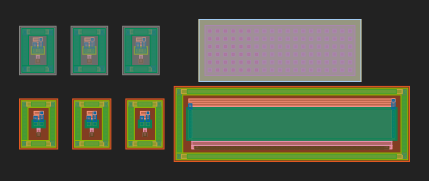

In [5]:
neurona_comp.show()
display_component(neurona_comp, scale=1, path=".")

In [6]:
# ADD AVDD & AVSS POWER RAILS AND CONNECT SUPPLY NODES
# =========================================================================

# Calculate full horizontal span of the cell to draw supply rails
bbox = evaluate_bbox(neurona_comp)
# → Obtiene el bounding box del componente neurona_comp (ancho total y alto)

top_y = neurona_comp.ymax + 2.0
# → Coordenada Y para la línea superior (AVDD), con margen extra de 3 µm

bottom_y = neurona_comp.ymin - 2.0
# → Coordenada Y para la línea inferior (AVSS), con margen extra de 3 µm

# Draw horizontal metal2 power rails
avdd_rail = neurona_comp << gf.components.rectangle(
    size=(bbox[0]+4, 1.0),              # Largo = ancho del layout + 4 µm, grosor = 1 µm
    layer=pdk.get_layer("met3")       # Se dibuja en la capa metal2
)
avdd_rail.move((-2, top_y))             # Se coloca en la parte superior (rail AVDD)

avss_rail = neurona_comp << gf.components.rectangle(
    size=(bbox[0]+4, 1.0),
    layer=pdk.get_layer("met3")
)
avss_rail.move((-2, bottom_y))          # Se coloca en la parte inferior (rail AVSS)

#adding a VIA M2M3 to the avdd avss pin, moving to the center of the rail
viam2m3 = via_stack(pdk, "met2", "met3", centered=True) #met2 is the bottom layer. met3 is the top layer.
viam2m5 = via_stack(pdk, "met2", "met4", centered=True) #met2 is the bottom layer. met5 is the top layer.

via_avdd = neurona_comp << viam2m5
via_avdd.move((bbox[0]/2, top_y + 0.5))
via_avss = neurona_comp << viam2m5
via_avss.move((bbox[0]/2, bottom_y + 0.5))

ComponentReference (parent Component "via_stack_0d486145", ports ['bottom_layer_W', 'bottom_layer_N', 'bottom_layer_E', 'bottom_layer_S', 'bottom_via_W', 'bottom_via_N', 'bottom_via_E', 'bottom_via_S', 'bottom_met_W', 'bottom_met_N', 'bottom_met_E', 'bottom_met_S', 'top_met_W', 'top_met_N', 'top_met_E', 'top_met_S'], origin (19.51, -1.5), rotation 0.0, x_reflection False)

2026-10-29 23:26:26.774 | INFO     | gdsfactory.klive:show:55 - Message from klive: {"version": "0.4.1", "klayout_version": "0.30.8", "type": "reload", "file": "/tmp/gdsfactory/neurona.gds"}


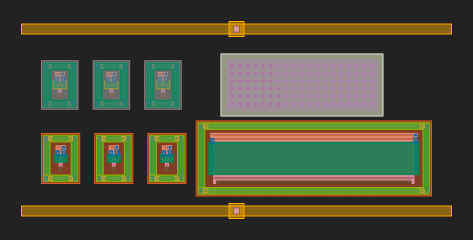

In [7]:
neurona_comp.show()
display_component(neurona_comp, scale=1, path=".")

In [8]:
#conectando todos los sustratos
#Transistores P
neurona_comp  << L_route(pdk, m1_ref.ports["tie_N_top_met_N"], via_avdd.ports["bottom_met_W"])
neurona_comp  << L_route(pdk, m3_ref.ports["tie_N_top_met_N"], via_avdd.ports["bottom_met_W"])
neurona_comp  << L_route(pdk, m6_ref.ports["tie_N_top_met_N"], via_avdd.ports["bottom_met_W"])

#Transistores N
neurona_comp  << L_route(pdk, m2_ref.ports["tie_S_top_met_S"], via_avss.ports["bottom_met_W"])
neurona_comp  << L_route(pdk, m4_ref.ports["tie_S_top_met_S"], via_avss.ports["bottom_met_W"])
neurona_comp  << L_route(pdk, m7_ref.ports["tie_S_top_met_S"], via_avss.ports["bottom_met_W"])
# --- Conexión del sustrato de M5 a VSS ---
neurona_comp << L_route(pdk,m5_ref.ports["tie_S_top_met_S"], via_avss.ports["bottom_met_W"] )

# conectar source con bulk
#Transistores N
neurona_comp << straight_route(pdk, m2_ref.ports["source_W"], m2_ref.ports["tie_W_top_met_E"])
neurona_comp << straight_route(pdk, m4_ref.ports["source_W"], m4_ref.ports["tie_W_top_met_E"])
neurona_comp << straight_route(pdk, m7_ref.ports["source_W"], m7_ref.ports["tie_W_top_met_E"])
# --- Conexión del bulk de M5 ---
neurona_comp << straight_route(pdk, m5_ref.ports["source_W"], m5_ref.ports["tie_W_top_met_E"])
#Transistores P
neurona_comp << straight_route(pdk, m1_ref.ports["source_W"], m1_ref.ports["tie_W_top_met_E"])
neurona_comp << straight_route(pdk, m3_ref.ports["source_W"], m3_ref.ports["tie_W_top_met_E"])
neurona_comp << straight_route(pdk, m6_ref.ports["source_W"], m6_ref.ports["tie_W_top_met_E"])


ComponentReference (parent Component "straight_route_5e99c53e", ports ['route_W', 'route_N', 'route_E', 'route_S'], origin (0.0, 0.0), rotation 0.0, x_reflection False)

2026-10-29 23:26:27.889 | INFO     | gdsfactory.klive:show:55 - Message from klive: {"version": "0.4.1", "klayout_version": "0.30.8", "type": "reload", "file": "/tmp/gdsfactory/neurona.gds"}


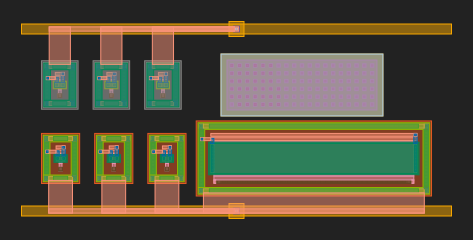

In [9]:
neurona_comp.show()
display_component(neurona_comp, scale=1, path=".")

In [10]:
#inversor 1 -------------------------------------------------------------------------------------------
neurona_comp << c_route(pdk, m1_ref.ports["multiplier_0_gate_W"], m2_ref.ports["multiplier_0_gate_W"], extension=1)
neurona_comp << c_route(pdk, m1_ref.ports["multiplier_0_drain_E"], m2_ref.ports["multiplier_0_drain_E"], extension=1)


# #inversor 2 -------------------------------------------------------------------------------------------
neurona_comp << c_route(pdk, m3_ref.ports["multiplier_0_gate_W"], m4_ref.ports["multiplier_0_gate_W"], extension=1)
neurona_comp << c_route(pdk, m3_ref.ports["multiplier_0_drain_E"], m4_ref.ports["multiplier_0_drain_E"], extension=1)


# #inversor 3 -------------------------------------------------------------------------------------------
neurona_comp << c_route(pdk, m6_ref.ports["multiplier_0_gate_W"], m7_ref.ports["multiplier_0_gate_W"], extension=1)
neurona_comp << c_route(pdk, m6_ref.ports["multiplier_0_drain_E"], m7_ref.ports["multiplier_0_drain_E"], extension=1)




# conexiones
neurona_comp << straight_route(pdk, m4_ref.ports["multiplier_0_gate_E"], m7_ref.ports["multiplier_0_gate_W"])

# M2 DRAIN und M4 GATE
via_m2_ref = neurona_comp << viam2m3
via_m2_ref.move(m2_ref.ports["multiplier_0_drain_E"].center).movex(2)

neurona_comp << straight_route(pdk, m2_ref.ports["multiplier_0_drain_E"], via_m2_ref.ports["bottom_met_W"])
neurona_comp << L_route(pdk, m4_ref.ports["multiplier_0_gate_W"], via_m2_ref.ports["bottom_met_S"])

# M5 DRAIN Und M2 GATE
viam5_ref = neurona_comp << viam2m3
viam5_ref.move(m5_ref.ports["multiplier_0_drain_W"].center).movex(-2)

viam2_ref =neurona_comp << viam2m3
viam2_ref.move(m2_ref.ports["multiplier_0_gate_W"].center).movex(-2)

neurona_comp << straight_route(pdk, m2_ref.ports["multiplier_0_gate_W"], viam2_ref.ports["bottom_met_E"])
neurona_comp << straight_route(pdk, m5_ref.ports["multiplier_0_drain_W"], viam5_ref.ports["bottom_met_E"])

neurona_comp << c_route(pdk, viam5_ref.ports["top_met_N"], viam2_ref.ports["top_met_N"],  e1glayer="met3", e2glayer="met3",cglayer="met2",extension=1)


# M5 GATE und M4 DRAIN
viam2m4 = via_stack(pdk, "met2", "met3", centered=True)
m5gate_via = neurona_comp << viam2m3
m5gate_via.move(m5_ref.ports["multiplier_0_gate_W"].center).movex(-2)

m4drain_via = neurona_comp << viam2m3
m4drain_via.move(m4_ref.ports["multiplier_0_drain_E"].center).movex(2)

neurona_comp << straight_route(pdk, m5_ref.ports["multiplier_0_gate_W"], m5gate_via.ports["bottom_met_E"])
neurona_comp << straight_route(pdk, m4_ref.ports["multiplier_0_drain_E"], m4drain_via.ports["bottom_met_W"])

neurona_comp << c_route(pdk, m5gate_via.ports["top_met_S"], m4drain_via.ports["top_met_S"],  e1glayer="met3", e2glayer="met3",cglayer="met3",extension=1)



ComponentReference (parent Component "c_route_d1026765", ports ['con_E', 'con_W'], origin (0.0, 0.0), rotation 0.0, x_reflection False)

2026-10-29 23:26:29.526 | INFO     | gdsfactory.klive:show:55 - Message from klive: {"version": "0.4.1", "klayout_version": "0.30.8", "type": "reload", "file": "/tmp/gdsfactory/neurona.gds"}


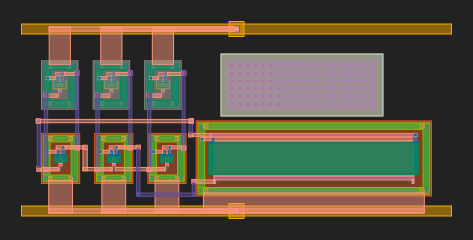

In [11]:
neurona_comp.show()
display_component(neurona_comp, scale=1, path=".")

In [12]:
print(cap_ref.ports)

{'array_row0_col0_bottom_layer_W': {'name': 'array_row0_col0_bottom_layer_W', 'width': 0.38, 'center': [18.85, 9.155], 'orientation': 180.0, 'layer': [70, 20], 'port_type': 'electrical'}, 'array_row0_col0_bottom_via_W': {'name': 'array_row0_col0_bottom_via_W', 'width': 0.2, 'center': [18.94, 9.155], 'orientation': 180.0, 'layer': [70, 44], 'port_type': 'electrical'}, 'array_row0_col0_bottom_met_W': {'name': 'array_row0_col0_bottom_met_W', 'width': 0.38, 'center': [18.85, 9.155], 'orientation': 180.0, 'layer': [70, 20], 'port_type': 'electrical'}, 'array_row0_col0_top_met_W': {'name': 'array_row0_col0_top_met_W', 'width': 0.34, 'center': [18.87, 9.155], 'orientation': 180.0, 'layer': [71, 20], 'port_type': 'electrical'}, 'array_row0_col1_bottom_layer_W': {'name': 'array_row0_col1_bottom_layer_W', 'width': 0.38, 'center': [19.63, 9.155], 'orientation': 180.0, 'layer': [70, 20], 'port_type': 'electrical'}, 'array_row0_col1_bottom_via_W': {'name': 'array_row0_col1_bottom_via_W', 'width': 0

In [13]:
# CAPACITOR CONECTIONS
m5_via = neurona_comp << viam2m3
m5_via.move(m5_ref.ports["multiplier_0_drain_E"].center).movex(1)

# superior a drain
neurona_comp << straight_route(pdk, m5_ref.ports["multiplier_0_drain_E"], m5_via.ports["bottom_met_W"])
neurona_comp << L_route(pdk,cap_ref.ports["top_met_E"],m5_via.ports["top_met_N"])

# inferior a vss
neurona_comp << L_route(pdk,cap_ref.ports["array_row0_col0_bottom_met_S"], via_avss.ports["top_met_E"])

#corregir DRC
cap_bbox = evaluate_bbox(cap_ref)
cap_m3 = neurona_comp << gf.components.rectangle(
    size=(cap_bbox[0]+0.5, cap_bbox[1]+0.5),              
    layer=pdk.get_layer("met3")       # Se dibuja en la capa metal3
)
cap_m3.move((cap_ref.center)).movex(-cap_bbox[0]/2 - 0.25).movey(-cap_bbox[1]/2 - 0.25)            # Se coloca en la parte superior (rail AVDD)



ComponentReference (parent Component "rectangle_85b0b276", ports ['e1', 'e2', 'e3', 'e4'], origin (17.71, 7.755000000000001), rotation 0.0, x_reflection False)

2026-10-29 23:26:30.390 | INFO     | gdsfactory.klive:show:55 - Message from klive: {"version": "0.4.1", "klayout_version": "0.30.8", "type": "reload", "file": "/tmp/gdsfactory/neurona.gds"}


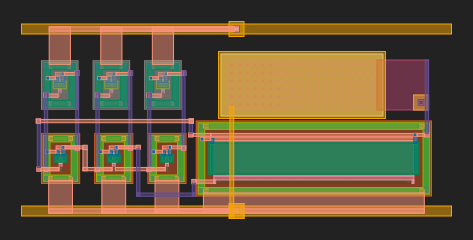

In [14]:
neurona_comp.show()
display_component(neurona_comp, scale=1, path=".")

In [15]:
#----------- Adding snippet code to move all the placed components to the proper position, 
#----------- in order to set origin into 0,0
# Place this snippet after all your material polygones are placed, and before your ports are placed
bbox = neurona_comp.bbox[0]
for ref in neurona_comp.references:
    ref.movex(-1*bbox[0]).movey(-1*bbox[1])

In [16]:
evaluate_bbox(neurona_comp)

(43.02, 19.705)

In [17]:
evaluate_bbox(neurona_comp)[0] * evaluate_bbox(neurona_comp)[1]

847.7091

In [18]:
# PORTS VIAS SPIKE, SPIKE_NEG und Iin
spike_via = neurona_comp << viam2m4
spike_via.move(m6_ref.ports["multiplier_0_drain_E"].center).movex(27.5)
spikeneg_via = neurona_comp << viam2m4
spikeneg_via.move(m6_ref.ports["multiplier_0_gate_E"].center).movex(27.785)
Iin_via = neurona_comp << viam2m4
Iin_via.move(m1_ref.ports["multiplier_0_gate_W"].center).movex(-2.5)

neurona_comp << straight_route(pdk, m6_ref.ports["multiplier_0_drain_E"], spike_via.ports["bottom_met_W"])
neurona_comp << straight_route(pdk, m6_ref.ports["multiplier_0_gate_E"], spikeneg_via.ports["bottom_met_W"])
neurona_comp << straight_route(pdk, m1_ref.ports["multiplier_0_gate_W"], Iin_via.ports["bottom_met_W"])



ComponentReference (parent Component "straight_route_036f5a70", ports ['route_W', 'route_N', 'route_E', 'route_S'], origin (0.0, 0.0), rotation 0.0, x_reflection False)

2026-10-29 23:26:31.038 | INFO     | gdsfactory.klive:show:55 - Message from klive: {"version": "0.4.1", "klayout_version": "0.30.8", "type": "reload", "file": "/tmp/gdsfactory/neurona.gds"}


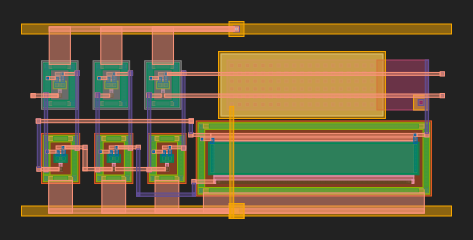

In [19]:
neurona_comp.show()
display_component(neurona_comp, scale=1, path=".")

In [20]:
# =========================================================================
# ADD PHYSICAL PINS AND LABELS FOR LVS
# =========================================================================

# Map port names to their source objects and properties
# Format: "pin_name": (source_object, orientation, port_layer, label_layer, mag)
pins_to_create = {
    "vdd":     (via_avdd, 180, "met3", "met4_label", 1.5),
    "vss":     (via_avss, 180, "met3", "met4_label", 1.5),
    "Iin":     (Iin_via, 180, "met2", "met3_label", 1.5),
    "spike_neg": (spikeneg_via, 180, "met2", "met3_label", 1.5),
    "spike": (spike_via, 270, "met2", "met3_label", 1.5)
}

for pin_name, (ref_obj, orient, p_layer, l_layer, mag) in pins_to_create.items():
    # Extract center position from the reference object
    center = ref_obj.center
    
    # 1. Add port
    neurona_comp.add_port(
        name=pin_name, 
        center=center, 
        width=1.0, 
        orientation=orient, 
        layer=pdk.get_layer(p_layer),  
        port_type="electrical"
    ) 

    # 2. Add text label on the corresponding label layer for net identity
    neurona_comp.add_label(
        text=pin_name, 
        position=center, 
        layer=pdk.get_glayer(l_layer), 
        magnification=mag
    )

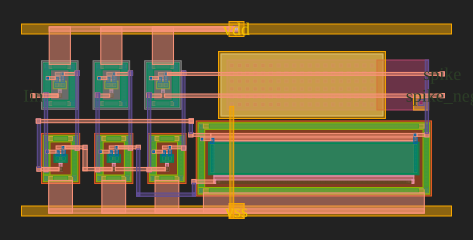

2026-10-29 23:26:31.480 | INFO     | gdsfactory.klive:show:55 - Message from klive: {"version": "0.4.1", "klayout_version": "0.30.8", "type": "reload", "file": "/tmp/gdsfactory/neurona.gds"}


In [21]:
display_component(neurona_comp, scale = 1,path=".")
neurona_comp.show()

In [22]:
neurona_comp.pprint_ports()

┏━━━━━━━━━━━┳━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━┓
┃ name      ┃ width ┃ center          ┃ orientation ┃ layer    ┃ port_type  ┃
┡━━━━━━━━━━━╇━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━┩
│ vdd       │ 1.0   │ [21.51, 18.955] │ 180         │ [70, 20] │ electrical │
│ vss       │ 1.0   │ [21.51, 0.75]   │ 180         │ [70, 20] │ electrical │
│ Iin       │ 1.0   │ [1.165, 12.29]  │ 180         │ [69, 20] │ electrical │
│ spike_neg │ 1.0   │ [42.1, 12.29]   │ 180         │ [69, 20] │ electrical │
│ spike     │ 1.0   │ [42.1, 14.465]  │ 270         │ [69, 20] │ electrical │
└───────────┴───────┴─────────────────┴─────────────┴──────────┴────────────┘

In [23]:
drc_result = pdk.drc_magic(neurona_comp, neurona_comp.name)

2026-10-29 23:26:36.199 | INFO     | gdsfactory.component:_write_library:1851 - Wrote to '/tmp/tmpr2shw46n/neurona.gds'


using default pdk_root
Defaulting to stale magic_commands.tcl

Magic 8.3 revision 636 - Compiled on Thu Apr 16 09:13:57 PM CEST 2026.
Starting magic under Tcl interpreter
Using the terminal as the console.
Using NULL graphics device.
Processing system .magicrc file
Switching to WIRING tool.
Switching to NETLIST tool.
Switching to PICK tool.
Switching to BOX tool.
Sourcing design .magicrc for technology sky130A ...
2 Magic internal units = 1 Lambda
Input style sky130(): scaleFactor=2, multiplier=2
The following types are not handled by extraction and will be treated as non-electrical types:
    ubm 
Scaled tech values by 2 / 1 to match internal grid scaling
Loading sky130A Device Generator Menu ...
Loading "/tmp/tmpr2shw46n/magic_commands.tcl" from command line.
Library written using GDS-II Release 6.0
Library name: library
Reading "neurona".
Reading "straight_route_282a8469".
Reading "straight_route_ddeb0624".
Reading "c_route_7298c5e2".
Reading "m4".
Reading "straight_route_ca2e5e9d".

In [ ]:
import os
from pathlib import Path
import tempfile
import subprocess

# Configuración de Magic
magicrc_file = Path(os.environ['PDKPATH']) / "libs.tech" / "magic" / f"{os.environ['PDK']}.magicrc"

# Nombre del diseño
design_name = neurona_comp.name

# Ruta donde guardas tus archivos
path_to_dir = "/foss/designs/libs/snn_analog/lif/"

# Archivos de salida
pex_path = path_to_dir + "spice/" + f"{design_name}.spice"
gds_path = path_to_dir + "gds/" + f"{design_name}.gds"
lef_path = path_to_dir + "lef/" + f"{design_name}.lef"

# Exportar GDS
neurona_comp.write_gds(str(gds_path))

#Script de Magic para extracción
magic_script_content = f"""
drc off            
gds flatglob *\\$\\$*
gds read {gds_path}

flatten {design_name}
load {design_name}
select top cell
extract do local
extract all
ext2sim labels on
ext2sim
extresist tolerance 10
extresist
ext2spice lvs
ext2spice cthresh 0
ext2spice extresist on
ext2spice -o {str(pex_path)}
port vdd use power
port vss use ground
lef write {str(lef_path)}
exit
"""



# Guardar script temporal
with tempfile.NamedTemporaryFile(mode='w', delete=False) as magic_script_file:
    magic_script_file.write(magic_script_content)
    magic_script_path = magic_script_file.name

# Ejecutar Magic en modo batch
magic_cmd = f"bash -c 'magic -rcfile {magicrc_file} -noconsole -dnull < {magic_script_path}'"
magic_subproc = subprocess.run(
    magic_cmd,
    shell=True,
    check=True,
    capture_output=True
)

# Capturar salida
magic_subproc_code = magic_subproc.returncode
magic_subproc_out = magic_subproc.stdout.decode('utf-8')
print(magic_subproc_out)


2026-10-30 00:02:47.174 | INFO     | gdsfactory.component:_write_library:1851 - Wrote to '/foss/designs/libs/snn_analog/lif/neurona.gds'



Magic 8.3 revision 636 - Compiled on Thu Apr 16 09:13:57 PM CEST 2026.
Starting magic under Tcl interpreter
Using the terminal as the console.
Using NULL graphics device.
Processing system .magicrc file
Switching to WIRING tool.
Switching to NETLIST tool.
Switching to PICK tool.
Switching to BOX tool.
Sourcing design .magicrc for technology sky130A ...
2 Magic internal units = 1 Lambda
Input style sky130(): scaleFactor=2, multiplier=2
The following types are not handled by extraction and will be treated as non-electrical types:
    ubm 
Scaled tech values by 2 / 1 to match internal grid scaling
Loading sky130A Device Generator Menu ...
Using technology "sky130A", version 1.0.575-2-g7b70722
Library written using GDS-II Release 6.0
Library name: library
Reading "neurona".
Reading "straight_route_282a8469".
Reading "straight_route_ddeb0624".
Reading "c_route_7298c5e2".
Reading "m4".
Reading "straight_route_ca2e5e9d".
Reading "L_route_a539dedf".
Reading "straight_route_8b06959e".
Reading 

In [30]:
import glob
extensions = [
            "els"
            "*.gds",
            "*.ext",
            "*.res.ext",
            "*.lvs.rpt",
            "*_lvs.rpt",
            "*.nodes",
            "*.sim",
            "*.pex.spice",
            "*_pex.spice"
            ]
files_to_delete = []
for ext in extensions:
    files_to_delete.extend(glob.glob(ext))
    
# Delete the files
for file_path in files_to_delete:
    try:
        os.remove(file_path)
        print(f"Deleted: {file_path}")
    except OSError as e:
        print(f"Error deleting {file_path}: {e}")

Deleted: L_route_171664f0.ext
Deleted: c_route_d11777e1.ext
Deleted: straight_route_21e65f9e.ext
Deleted: rectangle_b72df3f3$1.ext
Deleted: m4.ext
Deleted: straight_route_ddeb0624.ext
Deleted: L_route_804dd962.ext
Deleted: L_route_17258f58.ext
Deleted: straight_route_8c97da5f.ext
Deleted: straight_route_551e45df.ext
Deleted: straight_route_5e99c53e.ext
Deleted: straight_route_06d91427.ext
Deleted: via_stack_05d99bde.ext
Deleted: neurona.ext
Deleted: rectangle_b72df3f3.ext
Deleted: cap.ext
Deleted: m3.ext
Deleted: m1.ext
Deleted: c_route_bf0847fe.ext
Deleted: straight_route_1ce3acfd.ext
Deleted: L_route_c2c5dc9c.ext
Deleted: L_route_eeb94c01.ext
Deleted: L_route_fa611628.ext
Deleted: straight_route_8b06959e.ext
Deleted: straight_route_036f5a70.ext
Deleted: L_route_67cf513e.ext
Deleted: compass_b72df3f3.ext
Deleted: straight_route_e694242e.ext
Deleted: c_route_8bf6d516.ext
Deleted: straight_route_c3cebce7.ext
Deleted: straight_route_ca2e5e9d.ext
Deleted: m6.ext
Deleted: rectangle_85b0b27

In [27]:
# Ejecutar LVS con Netgen usando el PDK sky130
pdk.lvs_netgen(
    layout=neurona_comp,   # tu layout exportado
    design_name=neurona_comp.name,   # nombre del diseño
    pdk_root=Path(os.environ['PDKPATH']),   # raíz del PDK
    lvs_setup_tcl_file=Path(os.environ['PDKPATH']) / "libs.tech" / "netgen" / f"{os.environ['PDK']}_setup.tcl",
    
    # Netlist de referencia (esquemático ideal)
    lvs_schematic_ref_file=Path(path_to_dir +  "spice/" + "neurona.spice"),
    
    # Netlist extraído del layout (PEX/LVS)
    netlist=Path(path_to_dir + "sch/" + "neurona_sch.spice"),
    
    # Carpeta donde se guarda el reporte .lvs.rpt
    output_file_path= Path(str(path_to_dir))
)


2026-10-29 22:00:21.064 | INFO     | gdsfactory.component:_write_library:1851 - Wrote to '/tmp/tmpfuttnnpm/neurona.gds'


using user specified pdk_root, will search for required files in the specified directory

Magic 8.3 revision 636 - Compiled on Thu Apr 16 09:13:57 PM CEST 2026.
Starting magic under Tcl interpreter
Using the terminal as the console.
Using NULL graphics device.
Processing system .magicrc file
Switching to WIRING tool.
Switching to NETLIST tool.
Switching to PICK tool.
Switching to BOX tool.
Sourcing design .magicrc for technology sky130A ...
2 Magic internal units = 1 Lambda
Input style sky130(): scaleFactor=2, multiplier=2
The following types are not handled by extraction and will be treated as non-electrical types:
    ubm 
Scaled tech values by 2 / 1 to match internal grid scaling
Loading sky130A Device Generator Menu ...
Using technology "sky130A", version 1.0.575-2-g7b70722
Library written using GDS-II Release 6.0
Library name: library
Reading "neurona".
Reading "straight_route_282a8469".
Reading "straight_route_ddeb0624".
Reading "c_route_7298c5e2".
Reading "m4".
Reading "straight

{'magic_subproc_code': 0,
 'netgen_subproc_code': 0,
 'result_str': 'LVS run succeeded\nErrors found in LVS report: /tmp/tmpfuttnnpm/neurona_lvs.rpt'}